# Comparing the Explanations Across Models

Each model notebook explains one model on its own. This notebook puts all six side by side to answer three questions:

1. **Do the models look at the same words?** And how much do they rely on source fingerprints (like photo credits) rather than writing style?
2. **Do LIME and SHAP tell the same story?** If not, why not?
3. **Which model should we choose?** Comparing all six on both accuracy and explainability.

To make the comparison fair, every model is trained exactly as in its own notebook, and every model is explained on the same 200 test articles with the same LIME settings.

To summarise thousands of explanations, we sort words into the project's four word groups (defined in the README). They were fixed in advance, from what the EDA and the baseline notebook found:

| Group | Words | What is it |
|---|---|---|
| Source fingerprints | reuters, via, image, featured, getty, com, http, www, pic, twitter, wire, read, video, watch | Words from a website's page layout, not the story: photo credits ("Featured image via Getty Images"), links ("pic.twitter.com"), sign-offs ("21st Century Wire", "READ MORE"), embedded videos, and the publisher's own name. They show where an article came from, not whether it's true. |
| Wire-service style | said, told, minister, government, spokesman, presidential, representative, nov, monday–sunday | How Reuters writes: every claim is attributed to someone ("said on Tuesday"), official titles are used, and months are abbreviated. They point toward real. |
| Partisan/casual style | just, like, know, don, right, fact, gop, hillary, mr, breaking, even | How the fake sites write: conversational words, partisan names ("GOP" instead of "Republican", "Hillary" instead of "Clinton") and headline words like "breaking". They point toward fake. |
| Other words | every other word | The topic and content of the article itself: who and what it's about. |

## 1. Setup

In [1]:
import os, sys, json, time, warnings
if not os.path.exists("preprocessing.py"):
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..", "..")))
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
import joblib
import shap
from IPython.display import display
from scipy.stats import spearmanr
from lime.lime_text import LimeTextExplainer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from preprocessing import preprocess_text, get_split_tfidf, select_top_k_terms, RANDOM_STATE

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
RESULTS = {"random_state": RANDOM_STATE}

c:\Users\ADMIN\Desktop\XDS_project\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.1 Load the Data and Train the Six Models

Same data, preprocessing, split and settings as the model notebooks. The SVM takes about 15 minutes to train, so it is saved to a file after the first run and loaded from there on later runs. XGBoost uses dense arrays, as in its own notebook.

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv.gz")
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)
X_train, X_test, y_train, y_test, tfidf = get_split_tfidf(df)
feature_names = tfidf.get_feature_names_out()
vocab = tfidf.vocabulary_
test_text = df.loc[y_test.index, "processed_text"].reset_index(drop=True)
y_true = y_test.to_numpy()

t0 = time.time()
lr = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000).fit(X_train, y_train)
dt = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=RANDOM_STATE).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=200, max_depth=20, min_samples_leaf=5,
                            random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
lgbm = LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, max_depth=4, min_child_samples=50,
                      random_state=RANDOM_STATE, n_jobs=-1, verbose=-1).fit(X_train, y_train)
xgb = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, min_child_weight=10, tree_method="hist",
                    eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1).fit(X_train.toarray().astype(np.float32), y_train)

SVM_CACHE = "Model/XAI Synthesis/svm_rbf.joblib"
os.makedirs(os.path.dirname(SVM_CACHE), exist_ok=True)
if os.path.exists(SVM_CACHE):
    svm_model = joblib.load(SVM_CACHE)
else:
    svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE).fit(X_train, y_train)
    joblib.dump(svm_model, SVM_CACHE)
print(f"Models ready in {time.time() - t0:.0f} s")

Models ready in 554 s


In [3]:
# Fast exact SVM score, computed from the trained model's own parameters (checked against scikit-learn below)
_SV = sp.csr_matrix(svm_model.support_vectors_); _SVT = _SV.T.tocsr()
_sv_sq = np.asarray(_SV.multiply(_SV).sum(axis=1)).ravel()
_dual = np.asarray(sp.csr_matrix(svm_model.dual_coef_).todense()).ravel()
_b, _gamma = svm_model.intercept_[0], svm_model._gamma
def svm_decision(X):
    X = sp.csr_matrix(X)
    x_sq = np.asarray(X.multiply(X).sum(axis=1)).ravel()
    return np.exp(-_gamma * (x_sq[:, None] + _sv_sq[None, :] - 2 * (X @ _SVT).toarray())) @ _dual + _b
svm_score = svm_model.decision_function(X_test)
assert np.abs(svm_decision(X_test) - svm_score).max() < 1e-8
svm_pred = (svm_score > 0).astype(int)

def two_col(p):
    return np.column_stack([1 - p, p])

# Text in, fake/real scores out: one function per model, as LIME needs (SVM: sigmoid of its score, as in SVM.ipynb)
PREDICT = {
    "Logistic regression": lambda t: lr.predict_proba(tfidf.transform(t)),
    "Decision tree": lambda t: dt.predict_proba(tfidf.transform(t)),
    "Random Forest": lambda t: rf.predict_proba(tfidf.transform(t)),
    "LightGBM": lambda t: lgbm.predict_proba(tfidf.transform(t)),
    "XGBoost": lambda t: xgb.predict_proba(tfidf.transform(t).toarray().astype(np.float32)),
    "SVM (RBF)": lambda t: two_col(1 / (1 + np.exp(-svm_decision(tfidf.transform(t))))),
}
MODELS = list(PREDICT)

# The four word groups from the table above
FINGERPRINT = {"reuters", "via", "image", "images", "featured", "getty", "com", "http", "www", "pic", "twitter", "wire", "read", "video", "watch"}
WIRE = {"said", "told", "minister", "government", "spokesman", "presidential", "representative", "nov",
        "monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"}
PARTISAN = {"just", "like", "know", "don", "right", "fact", "gop", "hillary", "mr", "breaking", "even"}
CATS = ["Source fingerprints", "Wire-service style", "Partisan/casual style", "Other words"]
def category(w):
    return CATS[0] if w in FINGERPRINT else CATS[1] if w in WIRE else CATS[2] if w in PARTISAN else CATS[3]

## 2. The Articles We Explain

We pick 200 test articles, 100 fake and 100 real, and explain all six models on the same 200 with the same LIME settings (1,000 samples, top 10 words). So any difference between models comes from the models themselves, not from different articles or settings.

In [4]:
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = np.concatenate([rng.choice(np.where(y_true == c)[0], 100, replace=False) for c in (1, 0)])

t0 = time.time()
rows = []
for name in MODELS:
    explainer = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)
    for i in sample_idx:
        exp = explainer.explain_instance(test_text.iloc[i], PREDICT[name], num_features=10, num_samples=1000, labels=(1,))
        for rank, (word, weight) in enumerate(exp.as_list(label=1)):
            rows.append((name, int(i), word, weight, rank))
lime_all = pd.DataFrame(rows, columns=["model", "article", "word", "weight", "rank"])
lime_all["category"] = lime_all["word"].map(category)
lime_all["abs_weight"] = lime_all["weight"].abs()
print(f"LIME explanations for 6 models x 200 articles in {time.time() - t0:.0f} s")

LIME explanations for 6 models x 200 articles in 183 s


## 3. Do the Models Look at the Same Words?

### 3.1 Top 10 Words per Model

For each model, a word's importance is its average LIME weight (ignoring the sign) over the 200 articles. The sign in brackets shows which way it pushes on average: (+) toward fake, (−) toward real.

In [5]:
n_art = len(sample_idx)
glob = (lime_all.groupby(["model", "word"])
        .agg(importance=("abs_weight", lambda s: s.sum() / n_art), direction=("weight", "mean"))
        .reset_index())
top_table = {}
for m in MODELS:
    g = glob[glob.model == m].nlargest(10, "importance")
    top_table[m] = [f"{w} ({'+' if d > 0 else '−'})" for w, d in zip(g.word, g.direction)]
top_table = pd.DataFrame(top_table, index=range(1, 11))
display(top_table)

anchors = set.intersection(*[set(glob[glob.model == m].nlargest(15, "importance").word) for m in MODELS])
print("Words in the top 15 of all six models:", sorted(anchors))
for w in sorted(anchors):
    dirs = {m: float(glob[(glob.model == m) & (glob.word == w)].direction.iloc[0]) for m in MODELS}
    print(f"  {w:8s} pushes {'fake' if np.mean(list(dirs.values())) > 0 else 'real'} in {sum(np.sign(v) == np.sign(np.mean(list(dirs.values()))) for v in dirs.values())} of 6 models")
RESULTS["anchors_top15_all_models"] = sorted(anchors)

,Logistic regression,Decision tree,Random Forest,LightGBM,XGBoost,SVM (RBF)
1,said (−),said (−),said (−),said (−),said (−),said (−)
2,via (+),via (+),image (+),via (+),via (+),via (+)
3,video (+),video (+),via (+),video (+),video (+),image (+)
4,image (+),reuters (−),video (+),image (+),image (+),video (+)
5,hillary (+),qatar (+),featured (+),read (+),read (+),hillary (+)
6,mr (+),pope (−),getty (+),hillary (+),hillary (+),gop (+)
7,obama (+),egypt (+),watch (+),minister (−),minister (−),read (+)
8,thursday (−),colombia (−),like (+),watch (+),reuters (−),republican (−)
9,friday (−),guest (+),com (+),reuters (−),watch (+),thursday (−)
10,house (−),image (+),know (+),featured (+),thursday (−),wednesday (−)


Words in the top 15 of all six models: [np.str_('image'), np.str_('said'), np.str_('via'), np.str_('video')]
  image    pushes fake in 6 of 6 models
  said     pushes real in 6 of 6 models
  via      pushes fake in 6 of 6 models
  video    pushes fake in 6 of 6 models


Four words are in the top 15 of every model, and they push the same way every time: **said** toward real, and **via**, **image** and **video** toward fake. These are the shared core of all six models.

Below these four, each model family adds its own words:

- **Logistic regression and the SVM** add partisan names (hillary, gop, obama, mr) and weekdays.
- **LightGBM and XGBoost** add more fake-site layout words (read, watch) and reuters.
- **The Random Forest** adds the rest of the photo-credit line (featured, getty, com).
- **The decision tree's** list after rank 4 is noise. It only uses five terms, so words like qatar or pope get LIME weights close to zero.

### 3.2 How Much Each Model Relies on Each Word Group

For each model, the table shows what share of its total LIME weight falls on each word group. Two extra columns:

- **Top-5 words' share:** how much of the weight sits on the model's five most important words. High means the model relies on a few words; low means it spreads its decisions over many.
- **Photo-credit words' share:** the weight on image, via, featured and getty, the group whose grouped PFI the model notebooks report.

In [6]:
share = lime_all.groupby(["model", "category"])["abs_weight"].sum().unstack().reindex(columns=CATS).fillna(0)
share = share.div(share.sum(axis=1), axis=0).loc[MODELS]
concentration = pd.Series({m: glob[glob.model == m].nlargest(5, "importance").importance.sum() / glob[glob.model == m].importance.sum()
                           for m in MODELS}, name="Top-5 words' share")
photo_credit = {"image", "via", "featured", "getty"}
pc_share = (lime_all[lime_all.word.isin(photo_credit)].groupby("model")["abs_weight"].sum()
            / lime_all.groupby("model")["abs_weight"].sum()).loc[MODELS].rename("Photo-credit words' share")
display(pd.concat([share, concentration, pc_share], axis=1).round(3))
RESULTS["category_share_by_model"] = share.round(3).to_dict(orient="index")
RESULTS["photo_credit_share_by_model"] = pc_share.round(3).to_dict()
RESULTS["top5_concentration"] = concentration.round(3).to_dict()

,Source fingerprints,Wire-service style,Partisan/casual style,Other words,Top-5 words' share,Photo-credit words' share
Logistic regression,0.141,0.325,0.071,0.463,0.328,0.063
Decision tree,0.384,0.518,0.001,0.097,0.902,0.251
Random Forest,0.354,0.296,0.086,0.264,0.412,0.196
LightGBM,0.335,0.368,0.077,0.221,0.480,0.163
XGBoost,0.339,0.372,0.077,0.212,0.488,0.166
SVM (RBF),0.201,0.281,0.072,0.446,0.326,0.098


The biggest difference between models is how much they lean on source fingerprints:

| Model | Weight on source fingerprints |
|---|---|
| Decision tree | 38% |
| Random Forest, LightGBM, XGBoost | 34–35% |
| SVM | 20% |
| Logistic regression | 14% |

The SVM and logistic regression put most of their weight (45–46%) on "other words", meaning topic and content. They also spread it out: their top five words carry only 33% of the weight, against 41–49% for the tree ensembles and 90% for the decision tree. This explains why shuffling any single word barely changed the SVM's predictions in `SVM.ipynb`: there is always plenty of other evidence.

One more thing stands out. The photo-credit words get a slightly bigger share of LIME weight in the Random Forest (20%) than in LightGBM and XGBoost (16–17%), yet removing them costs the boosted models about three times as much recall (grouped PFI of 0.061 and 0.058, against 0.019). So how much a model *uses* a word is not the same as how much it *depends* on it. The forest uses the photo credit just as much, but has other words to fall back on when it's gone.

### 3.3 How Similar Are the Models' Explanations?

For each pair of models, we check whether they rank the same words as important. The number is a rank correlation (Spearman): 1 means the same words in the same order, 0 means no relation, and a negative value means opposite orders. It is computed over the 20 most important words of the two models combined.

In [11]:
glob["importance"] = glob["importance"].abs()                     # direction doesn't matter
P = glob.pivot(index="word", columns="model", values="importance").fillna(0)

top = {m: set(glob[(glob.model == m) & (glob.importance > 0)]
              .nlargest(20, "importance").word) for m in MODELS}   # no zero-importance filler

sim = pd.DataFrame(index=MODELS, columns=MODELS, dtype=float)
for a in MODELS:
    for b in MODELS:
        union = list(top[a] | top[b])
        sim.loc[a, b] = spearmanr(P.loc[union, a], P.loc[union, b]).correlation

display(sim.round(2))
RESULTS["model_similarity_spearman"] = sim.round(2).to_dict(orient="index")

,Logistic regression,Decision tree,Random Forest,LightGBM,XGBoost,SVM (RBF)
Logistic regression,1.00,-0.21,-0.08,0.14,0.21,0.67
Decision tree,-0.21,1.00,-0.13,-0.16,-0.17,-0.21
Random Forest,-0.08,-0.13,1.00,0.52,0.52,0.10
LightGBM,0.14,-0.16,0.52,1.00,0.94,0.34
XGBoost,0.21,-0.17,0.52,0.94,1.00,0.37
SVM (RBF),0.67,-0.21,0.10,0.34,0.37,1.00


Models from the same family explain themselves alike:

- **LightGBM and XGBoost** are almost identical (0.95), and fairly close to the Random Forest (0.56–0.57).
- **The SVM is closest to logistic regression** (0.69). That fits `SVM.ipynb`, where the SVM's ALE and ICE curves were almost straight lines, as in a linear model.
- **The decision tree** matches nothing, because its whole explanation is just five words.

Accuracy doesn't tell you any of this. The SVM (0.984) and XGBoost (0.980) are almost equally accurate, but they reach their answers through quite different words (0.36). So knowing a model is accurate doesn't tell a reviewer what its flags are based on.

## 4. Do LIME and SHAP Tell the Same Story?

The two methods ask slightly different questions:

- **LIME** (and the KernelSHAP setup used for the SVM) asks: *"What happens if we delete this word from the article?"* So it can only say something about words that are in the article.
- **TreeSHAP** (and SHAP for a linear model) asks: *"How does this article differ from an average training article?"* So a word that is **missing** can also matter. For example, an article can look real partly because it has no photo credit.

First we measure how much of SHAP's explanation is about missing words.

In [8]:
# (a) share of SHAP's attribution that goes to words NOT in the article (same 200 articles)
Xs = X_test[sample_idx].toarray()
present = Xs > 0
absence = {}
for name, model, X_in in [("Decision tree", dt, Xs), ("Random Forest", rf, Xs), ("LightGBM", lgbm, Xs), ("XGBoost", xgb, Xs.astype(np.float32))]:
    v = shap.TreeExplainer(model).shap_values(X_in, check_additivity=False)
    v = v[1] if isinstance(v, list) else (v[:, :, 1] if np.ndim(v) == 3 else v)
    absence[name] = np.abs(v[~present]).sum() / np.abs(v).sum()
    if name == "LightGBM":
        lgbm_shap = v
mu = np.asarray(X_train.mean(axis=0)).ravel()
v_lin = lr.coef_[0] * (Xs - mu)                     # exact SHAP for a linear model
absence["Logistic regression (linear SHAP)"] = np.abs(v_lin[~present]).sum() / np.abs(v_lin).sum()
absence = pd.Series(absence, name="share of |SHAP| on missing words")
display(absence.round(3))
absent_terms = pd.Series(np.where(~present, np.abs(lgbm_shap), 0).sum(axis=0), index=feature_names)
absent_terms = (absent_terms / np.abs(lgbm_shap).sum()).nlargest(6)
print("LightGBM: missing words with the most attribution (share of all |SHAP|):")
print(absent_terms.round(3).to_string())
RESULTS["shap_absence_share"] = absence.round(3).to_dict()
RESULTS["lgbm_top_absent_terms"] = absent_terms.round(3).to_dict()

Decision tree                        0.450
Random Forest                        0.478
LightGBM                             0.459
XGBoost                              0.440
Logistic regression (linear SHAP)    0.490
Name: share of |SHAP| on missing words, dtype: float64

LightGBM: missing words with the most attribution (share of all |SHAP|):
via         0.056
said        0.038
image       0.034
video       0.028
featured    0.024
reuters     0.014


For every tree model and for logistic regression, **44–49% of SHAP's explanation is about words the article doesn't contain.** For LightGBM, the biggest of these are the missing photo-credit words and a missing "said": via (5.6% of all attribution), said (3.8%), image (3.4%) and video (2.8%).

In other words, nearly half of what SHAP reports is "this article looks real partly because it has no photo credit", or "looks fake partly because it never says *said*". LIME can't show this half, because it only deletes words that are there. A reviewer who only sees highlighted words in the text only sees half the reasons.

The SVM isn't in the list because its KernelSHAP setup works like LIME: it only switches off words that are in the article, so a missing word always gets zero.

Next, we compare LIME and SHAP on the words that **are** in the article, for 100 of the 200 articles (50 fake, 50 real). We use four measures:

- **Rank agreement (Spearman):** do they put the words in the same order? 1 means identical.
- **Same sign:** the share of words both methods push in the same direction.
- **Same top word:** the share of articles where both pick the same most important word.
- **Top-3 overlap:** how much the two top-3 lists overlap, from 0 (no shared words) to 1 (the same three words).

In [9]:
# (b) LIME vs SHAP on the words PRESENT in each article
top_idx, top_terms, _ = select_top_k_terms(X_train, y_train, feature_names, k=30, method="chi2")
def kernel_shap_topk(x_row, nsamples=500, seed=RANDOM_STATE):
    def f(Z):
        full = np.tile(x_row, (Z.shape[0], 1)); full[:, top_idx] = Z
        return svm_decision(full)
    np.random.seed(seed)
    ex = shap.KernelExplainer(f, np.zeros((1, len(top_idx))))
    return ex.shap_values(x_row[top_idx].reshape(1, -1), nsamples=nsamples, silent=True)[0]

def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else np.nan

sub = np.concatenate([sample_idx[:50], sample_idx[100:150]])
lgbm_pos = {i: k for k, i in enumerate(sample_idx)}
explainer = LimeTextExplainer(class_names=["real", "fake"], random_state=RANDOM_STATE)
t0, rows = time.time(), []
for i in sub:
    text = test_text.iloc[i]
    n_words = len(set(text.split()))
    # SVM: LIME vs KernelSHAP on the top-30 terms present in the article
    lw = dict(explainer.explain_instance(text, PREDICT["SVM (RBF)"], num_features=n_words, num_samples=1000, labels=(1,)).as_list(label=1))
    ks = kernel_shap_topk(Xs[lgbm_pos[i]])
    pres = [j for j in range(len(top_idx)) if Xs[lgbm_pos[i], top_idx[j]] > 0 and top_terms[j] in lw]
    if len(pres) >= 3:
        a, b = [lw[top_terms[j]] for j in pres], [ks[j] for j in pres]
        rows.append({"pair": "SVM: LIME vs KernelSHAP", "spearman": spearmanr(a, b).correlation,
                     "sign_agreement": np.mean(np.sign(a) == np.sign(b)),
                     "same_top_word": np.argmax(np.abs(a)) == np.argmax(np.abs(b)),
                     "top3_jaccard": jaccard([top_terms[pres[k]] for k in np.argsort(-np.abs(a))[:3]],
                                             [top_terms[pres[k]] for k in np.argsort(-np.abs(b))[:3]])})
    # LightGBM: LIME vs TreeSHAP on all words present in the article
    lw = dict(explainer.explain_instance(text, PREDICT["LightGBM"], num_features=n_words, num_samples=1000, labels=(1,)).as_list(label=1))
    words = [w for w in set(text.split()) if w in vocab and w in lw]
    a, b = np.array([lw[w] for w in words]), np.array([lgbm_shap[lgbm_pos[i], vocab[w]] for w in words])
    nz = np.abs(b) > 1e-9
    rows.append({"pair": "LightGBM: LIME vs TreeSHAP", "spearman": spearmanr(a, b).correlation,
                 "sign_agreement": np.mean(np.sign(a[nz]) == np.sign(b[nz])) if nz.any() else np.nan,
                 "same_top_word": np.argmax(np.abs(a)) == np.argmax(np.abs(b)),
                 "top3_jaccard": jaccard([words[k] for k in np.argsort(-np.abs(a))[:3]], [words[k] for k in np.argsort(-np.abs(b))[:3]]),
                 "share_present_words_with_zero_shap": 1 - nz.mean()})
agree = pd.DataFrame(rows)
summary = agree.groupby("pair").agg(["mean", "count"]).round(3)
display(summary)
print(f"done in {time.time() - t0:.0f} s")
RESULTS["lime_vs_shap"] = {p: g.drop(columns="pair").mean().round(3).to_dict() | {"n_articles": int(len(g))} for p, g in agree.groupby("pair")}

spearman       sign_agreement       same_top_word       top3_jaccard       share_present_words_with_zero_shap      
                               mean count           mean count          mean count         mean count                               mean count
pair                                                                                                                                          
LightGBM: LIME vs TreeSHAP    0.311   100          0.663   100           0.6   100        0.734   100                              0.695   100
SVM: LIME vs KernelSHAP       0.961    75          0.941    75           1.0    75        0.953    75                                NaN     0

done in 48 s


**When the two methods ask the same question, they agree almost perfectly.** For the SVM, LIME and KernelSHAP both measure what happens when a word is deleted, and:

| Measure | SVM: LIME vs KernelSHAP | LightGBM: LIME vs TreeSHAP |
|---|---|---|
| Rank agreement | 0.96 | 0.31 |
| Same sign | 94% | 66% |
| Same top word | 100% (75 of 75 articles) | 60% |
| Top-3 overlap | 0.95 | 0.73 |

For LightGBM the agreement is much weaker, although the top three words still mostly overlap. This isn't random noise; it comes from how the two methods work. 70% of the words in an article are never used by LightGBM's trees, so TreeSHAP gives them exactly zero. LIME, by contrast, gives every word some weight, because deleting any word changes the TF-IDF weights of the others.

So neither method is wrong. LIME answers "what if this word were deleted?", TreeSHAP answers "how does this article differ from an average one?", and each gives only part of the picture.

(The SVM comparison covers 75 articles, not 100, because it needs at least three of the top-30 terms in the article.)

## 5. Choosing a Model: Accuracy vs Explainability

A good model for a fact-checking team needs two things: it should catch fake articles, and a reviewer should be able to see why it flagged one. The table puts both side by side for all six models:

- **Accuracy, fake recall, missed fakes, false alarms:** how well the model works (from the test set).
- **Weight on fingerprints:** how much of its reasoning rests on source fingerprints such as photo credits, rather than on how the article is written (from Section 3.2). Lower is better.
- **Top-5 words' share:** how much it relies on just a few words (from Section 3.2). Lower means it spreads its decisions over more evidence.
- **How it is explained:** whether we can read its reasons exactly, or only estimate them with LIME and SHAP.

In [10]:
from sklearn.metrics import accuracy_score, recall_score

preds = {
    "Logistic regression": lr.predict(X_test),
    "Decision tree": dt.predict(X_test),
    "Random Forest": rf.predict(X_test),
    "LightGBM": lgbm.predict(X_test),
    "XGBoost": xgb.predict(X_test.toarray().astype(np.float32)),
    "SVM (RBF)": svm_pred,
}
how = {
    "Logistic regression": "exact (coefficients)",
    "Decision tree": "exact (readable tree)",
    "Random Forest": "estimated (LIME, SHAP)",
    "LightGBM": "estimated (LIME, SHAP)",
    "XGBoost": "estimated (LIME, SHAP)",
    "SVM (RBF)": "estimated (LIME, KernelSHAP)",
}
choice = pd.DataFrame({
    "Accuracy": {m: accuracy_score(y_true, p) for m, p in preds.items()},
    "Fake recall": {m: recall_score(y_true, p) for m, p in preds.items()},
    "Missed fakes": {m: int(((y_true == 1) & (p == 0)).sum()) for m, p in preds.items()},
    "False alarms": {m: int(((y_true == 0) & (p == 1)).sum()) for m, p in preds.items()},
    "Weight on fingerprints": share[CATS[0]],
    "Top-5 words' share": concentration,
    "How it is explained": pd.Series(how),
}).loc[MODELS]
display(choice.round(3))
RESULTS["model_choice_table"] = choice.round(3).to_dict(orient="index")

,Accuracy,Fake recall,Missed fakes,False alarms,Weight on fingerprints,Top-5 words' share,How it is explained
Logistic regression,0.980,0.969,108,44,0.141,0.328,exact (coefficients)
Decision tree,0.882,0.923,269,639,0.384,0.902,exact (readable tree)
Random Forest,0.966,0.935,228,33,0.354,0.412,"estimated (LIME, SHAP)"
LightGBM,0.980,0.966,119,35,0.335,0.480,"estimated (LIME, SHAP)"
XGBoost,0.980,0.965,122,33,0.339,0.488,"estimated (LIME, SHAP)"
SVM (RBF),0.984,0.975,87,39,0.201,0.326,"estimated (LIME, KernelSHAP)"


The models fall into three groups:

- **Decision tree:** fully readable, but too inaccurate (88% accuracy, 269 missed fakes).
- **Random Forest, LightGBM, XGBoost:** black boxes that lean hardest on fingerprints (34–35% of their weight). LightGBM and XGBoost match the baseline's accuracy, but they get there largely through the photo credit, and the Random Forest misses twice as many fakes.
- **Logistic regression and SVM:** the two best options. Both are highly accurate, and both rely least on fingerprints (14% and 20%) and spread their decisions over many words.

Between the last two, it's a trade-off:

- **The SVM** is the most accurate model (98.4%) and misses the fewest fakes (87), but it's a black box, so its reasons can only be estimated.
- **Logistic regression** is almost as accurate (98.0%, 108 missed fakes) and fully transparent: its coefficients give its exact reasons, with no estimating.

Taking both into account, **we choose logistic regression.** Compared with the SVM, it gives up only 0.4 points of accuracy (21 more missed fakes out of 3,489). In return, every flag can be explained exactly from its coefficients, and it relies less on source fingerprints than any other model. For a fact-checking team that has to justify why an article was flagged, that transparency is worth more than the small gain in accuracy.

## 6. Figure for the Report

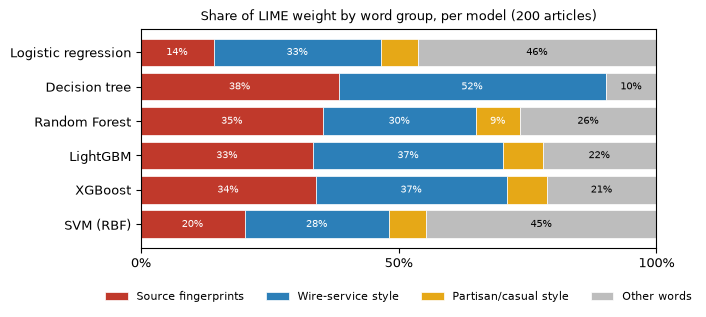

In [12]:
plt.rcParams.update({"font.size": 9})
colors = ["#c0392b", "#2c7fb8", "#e6a817", "#bdbdbd"]
fig, ax = plt.subplots(figsize=(7, 3.3))
left = np.zeros(len(share))
for c, col in zip(CATS, colors):
    ax.barh(range(len(share)), share[c].values, left=left, color=col, label=c, edgecolor="white", linewidth=0.5)
    for k, (l, v) in enumerate(zip(left, share[c].values)):
        if v >= 0.08:
            ax.text(l + v / 2, k, f"{v:.0%}", ha="center", va="center", fontsize=7.5,
                    color="white" if col != "#bdbdbd" else "black")
    left += share[c].values
ax.set_yticks(range(len(share))); ax.set_yticklabels(share.index); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.set_xticks([0, 0.5, 1]); ax.set_xticklabels(["0%", "50%", "100%"])
ax.set_title("Share of LIME weight by word group, per model (200 articles)", fontsize=9.5)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, fontsize=8, frameon=False)
plt.tight_layout()
plt.show()
plt.rcParams.update({"font.size": 10})

## 7. All Numbers in One Place

Every number used in this notebook, printed together so the report can be checked against it.

In [13]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple, set)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, np.generic):
        return o.item()
    return o
print(json.dumps(to_jsonable(RESULTS), indent=2))

{
  "random_state": 42,
  "anchors_top15_all_models": [
    "image",
    "said",
    "via",
    "video"
  ],
  "category_share_by_model": {
    "Logistic regression": {
      "Source fingerprints": 0.141,
      "Wire-service style": 0.325,
      "Partisan/casual style": 0.071,
      "Other words": 0.463
    },
    "Decision tree": {
      "Source fingerprints": 0.384,
      "Wire-service style": 0.518,
      "Partisan/casual style": 0.001,
      "Other words": 0.097
    },
    "Random Forest": {
      "Source fingerprints": 0.354,
      "Wire-service style": 0.296,
      "Partisan/casual style": 0.086,
      "Other words": 0.264
    },
    "LightGBM": {
      "Source fingerprints": 0.335,
      "Wire-service style": 0.368,
      "Partisan/casual style": 0.077,
      "Other words": 0.221
    },
    "XGBoost": {
      "Source fingerprints": 0.339,
      "Wire-service style": 0.372,
      "Partisan/casual style": 0.077,
      "Other words": 0.212
    },
    "SVM (RBF)": {
      "Source fi